# Predictive Maintenance for Oil Field Equipment Using Machine Learning

**Goal.** Use equipment sensor data to identify patterns associated with elevated failure risk, and
turn them into a ranked list that helps maintenance teams decide what to look at first.

**What this is - and is not.**

* This is a portfolio analysis on **synthetic data**. The data is generated by
  `src/pdm/data_generation.py`; it does not come from real equipment or any company.
* The output is a **decision-support indicator**. It does not determine whether equipment is
  failing, does not declare anything unsafe and does not issue maintenance instructions.
* Every number below is computed when the notebook is executed. Nothing is typed in by hand.

**Contents**

1. Setup and data
2. Data validation
3. Exploratory analysis
4. Feature engineering (and how leakage is prevented)
5. Validation design
6. Models
7. Evaluation
8. Interpretation: what the model uses, where it works, where it fails
9. Risk ranking
10. Robustness checks
11. Limitations and business reading

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from pdm import config as C
from pdm import (data_loading, validation, features, splitting, modeling, evaluation, risk,
                 plotting, pipeline)

pd.set_option("display.max_columns", 60, "display.width", 200, "display.float_format", "{:,.4f}".format)
%matplotlib inline


def show(fig):
    # display a figure returned by pdm.plotting inline, then release it
    display(fig)
    plt.close(fig)

## 1. Setup and data

The pipeline (`python scripts/run_pipeline.py`) has already written the raw files. `stage_data`
loads them, measures data-quality problems and applies the documented cleaning decisions.

Four tables mirror what a maintenance organisation typically holds: hourly **telemetry**, an
**equipment registry**, a **maintenance log** and a **failure log**.

In [2]:
data = pipeline.stage_data(regenerate=False)
raw = data.raw
for name in ("telemetry", "registry", "maintenance", "failures"):
    print(f"{name:12s} {raw[name].shape}")
raw["telemetry"].sort_values(["equipment_id", "timestamp"]).head()

[03:50:47] Loaded 519,474 telemetry rows; validating ...


telemetry    (519474, 10)
registry     (60, 5)
maintenance  (292, 5)
failures     (156, 3)


,timestamp,equipment_id,equipment_type,temperature_c,vibration_mm_s,pressure_kpa,rotational_speed_rpm,load_pct,ambient_temp_c,operating_hours
459712,2024-01-01 00:00:00,CMP-001,compressor,83.8300,3.6930,"6,041.8000",929.1000,47.2000,-15.8000,"4,482.0000"
38402,2024-01-01 01:00:00,CMP-001,compressor,82.8500,3.1730,"6,201.3000",926.9000,47.5500,-17.7000,"4,483.0000"
215501,2024-01-01 02:00:00,CMP-001,compressor,82.0400,3.2340,"6,201.1000",932.7000,46.1400,-17.4000,"4,484.0000"
419220,2024-01-01 03:00:00,CMP-001,compressor,82.0400,3.5960,"6,205.6000",925.0000,48.2400,-16.7000,"4,485.0000"
298825,2024-01-01 04:00:00,CMP-001,compressor,82.0300,3.3610,"6,189.8000",933.2000,48.4300,-18.5000,"4,486.0000"


In [3]:
display(raw["registry"].groupby("equipment_type").agg(units=("equipment_id", "count"),
        median_rated_kw=("rated_power_kw", "median")))
display(raw["maintenance"]["maintenance_type"].value_counts().to_frame("work_orders"))
display(data.failures["failure_mode"].value_counts().to_frame("failures"))

,units,median_rated_kw
equipment_type,,
compressor,20,"1,278.5000"
motor,20,430.5000
pump,20,236.5000


,work_orders
maintenance_type,
corrective,153
preventive,139


,failures
failure_mode,
bearing_wear,63
pressure_loss,44
overheating,35
sudden_no_precursor,11


## 2. Data validation

The generator deliberately injects realistic problems - duplicates, sentinel values, impossible
readings, sensor dropouts, a mislabelled equipment type, an hour-meter reset, duplicated failure
records - so this stage has real work to do. `validate_raw` only *measures*; `clean_telemetry`
applies the decisions.

In [4]:
f = data.findings
summary = pd.Series({
    "telemetry rows (raw)": f["n_rows"],
    "units": f["n_units"],
    "exact duplicate rows": f["exact_duplicate_rows"],
    "equipment-type mismatches vs registry": f["equipment_type_mismatches"],
    "units with operating-hours counter reset": len(f["operating_hours_resets"]),
    "gaps > 1 h": f["coverage_gaps"],
    "gaps not explained by a maintenance outage": f["coverage_gaps_unexplained"],
    "duplicate failure records": f["duplicate_failure_records"],
    "failures without corrective work order": f["failures_without_corrective_record"],
}, name="count")
display(summary.to_frame())
quality = pd.DataFrame({"missing (raw)": pd.Series(f["missing_values"]),
                        "out of physical range": pd.Series(f["out_of_range"])}).loc[C.SENSORS].fillna(0).astype(int)
quality["filled by 6 h forward-fill"] = pd.Series(data.clean_log["forward_filled"])
quality["still missing"] = pd.Series(data.clean_log["still_missing_after_ffill"])
quality

,count
telemetry rows (raw),519474
units,60
exact duplicate rows,300
equipment-type mismatches vs registry,40
units with operating-hours counter reset,2
gaps > 1 h,292
gaps not explained by a maintenance outage,0
duplicate failure records,3
failures without corrective work order,0


,missing (raw),out of physical range,filled by 6 h forward-fill,still missing
temperature_c,2203,150,2256,96
vibration_mm_s,2224,120,2223,121
pressure_kpa,2176,100,2193,82
rotational_speed_rpm,2258,0,2105,152
load_pct,2077,0,2076,0


**Decisions** (full reasoning in `reports/data_validation_report.md`):

| Problem | Decision | Why |
|---|---|---|
| Exact duplicates | Drop | They carry no information and would double-weight rows. |
| Out-of-range readings | Set to missing, do not clip | A clipped value looks like a genuine extreme reading. |
| Short gaps | Forward-fill within the unit, max 6 h | Uses only the past. No back-fill or interpolation - both use future readings. |
| Long dropouts | Leave missing | Rolling statistics skip them; models impute with training medians. |
| Type mismatch | Trust the registry | One system of record. |
| Hour-meter reset | Re-base the counter | Keeps it monotonic. |
| Downtime gaps | Keep as gaps | The unit was not running; inventing rows would be fabrication. |

## 3. Exploratory analysis

### 3.1 Sensor distributions

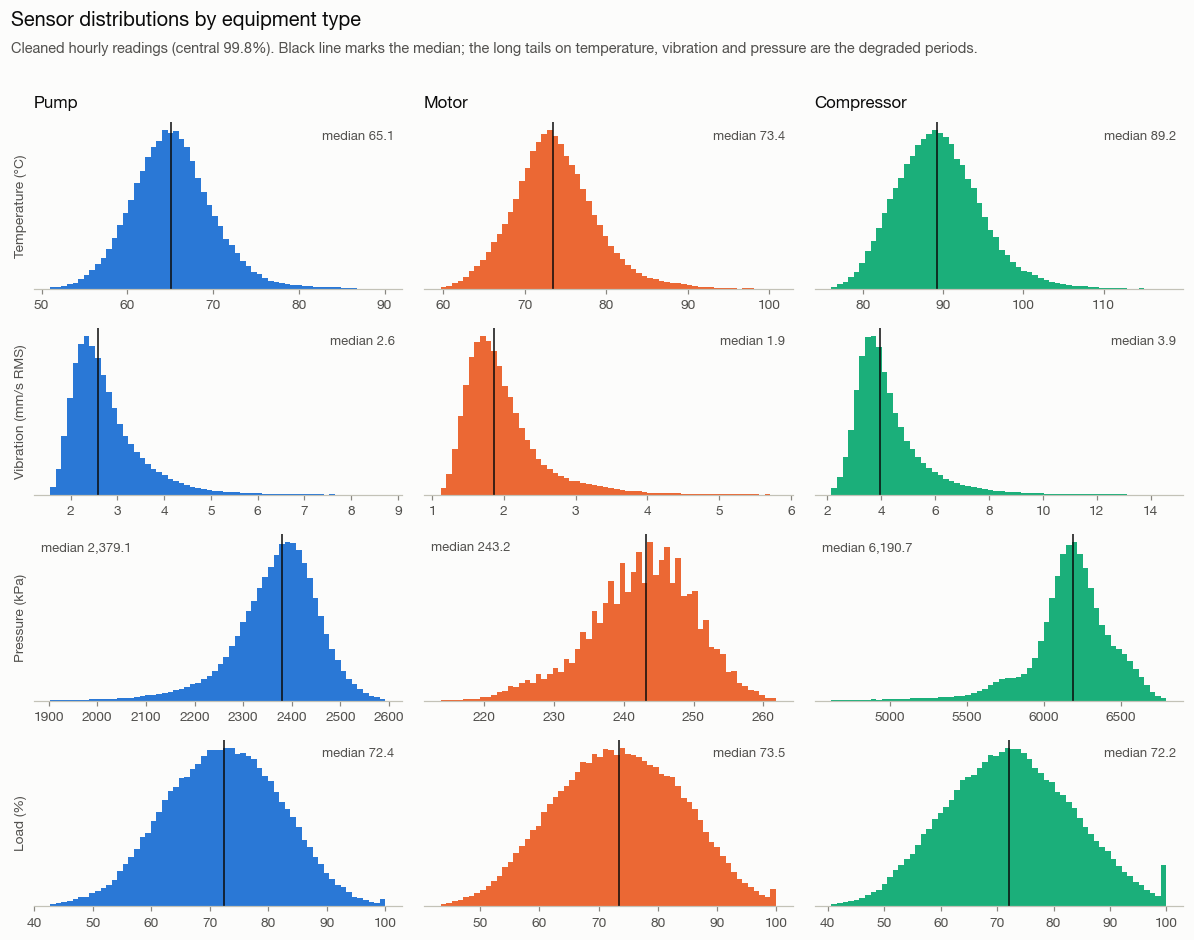

In [5]:
tele = data.telemetry
show(plotting.fig_sensor_distributions(tele))

Pressure and speed sit at completely different levels for each equipment type, and even within a
type each unit has its own normal level. An absolute alarm limit therefore means different things
on different machines - the motivation for expressing features relative to each unit's own baseline.

### 3.2 Failure patterns

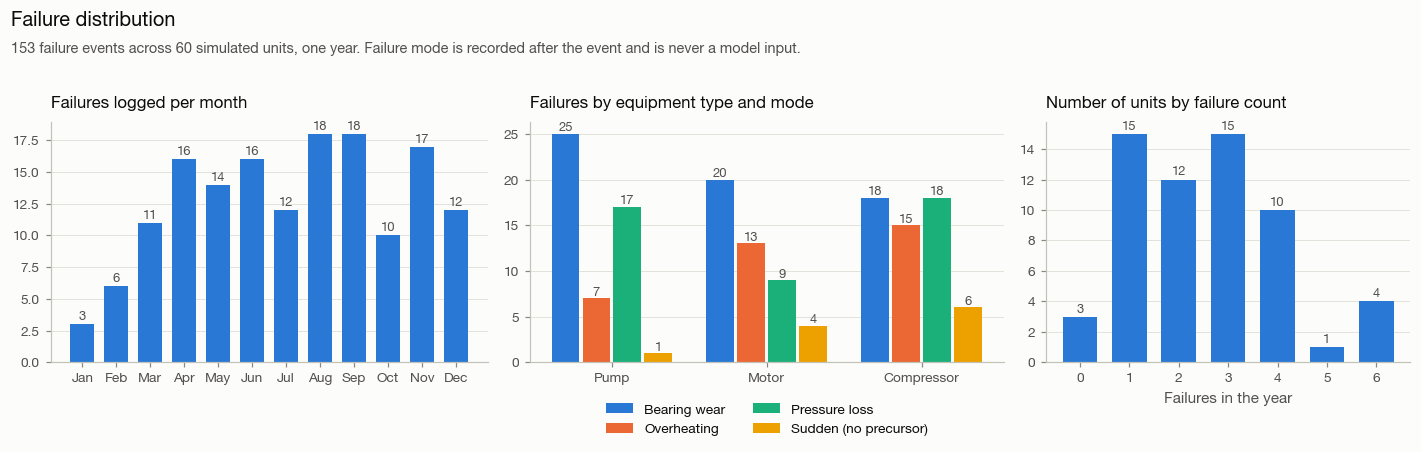

In [6]:
show(plotting.fig_failure_distribution(data.failures, data.registry))

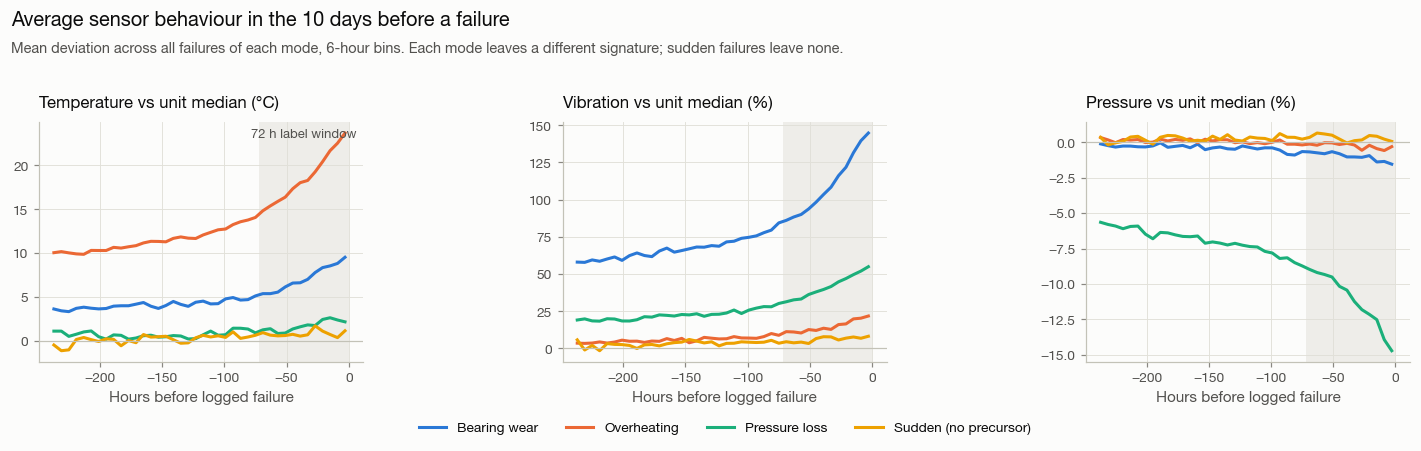

In [7]:
show(plotting.fig_pre_failure_trends(tele, data.failures))

Reading the chart above:

* **Each failure mode has its own signature** - temperature for overheating, vibration for bearing
  wear, falling pressure for pressure loss. No single sensor covers all three.
* **The drift starts well before the 72-hour window and accelerates inside it.** Units look
  "degraded" for days or weeks before failing. That is the central difficulty of the task:
  *degraded* is not the same as *about to fail in the next 72 hours*.
* **Sudden failures show nothing.** No model that reads these sensors can anticipate them.

These are associations in simulated data, described so the modelling choices make sense - not claims
about physical cause on real machines.

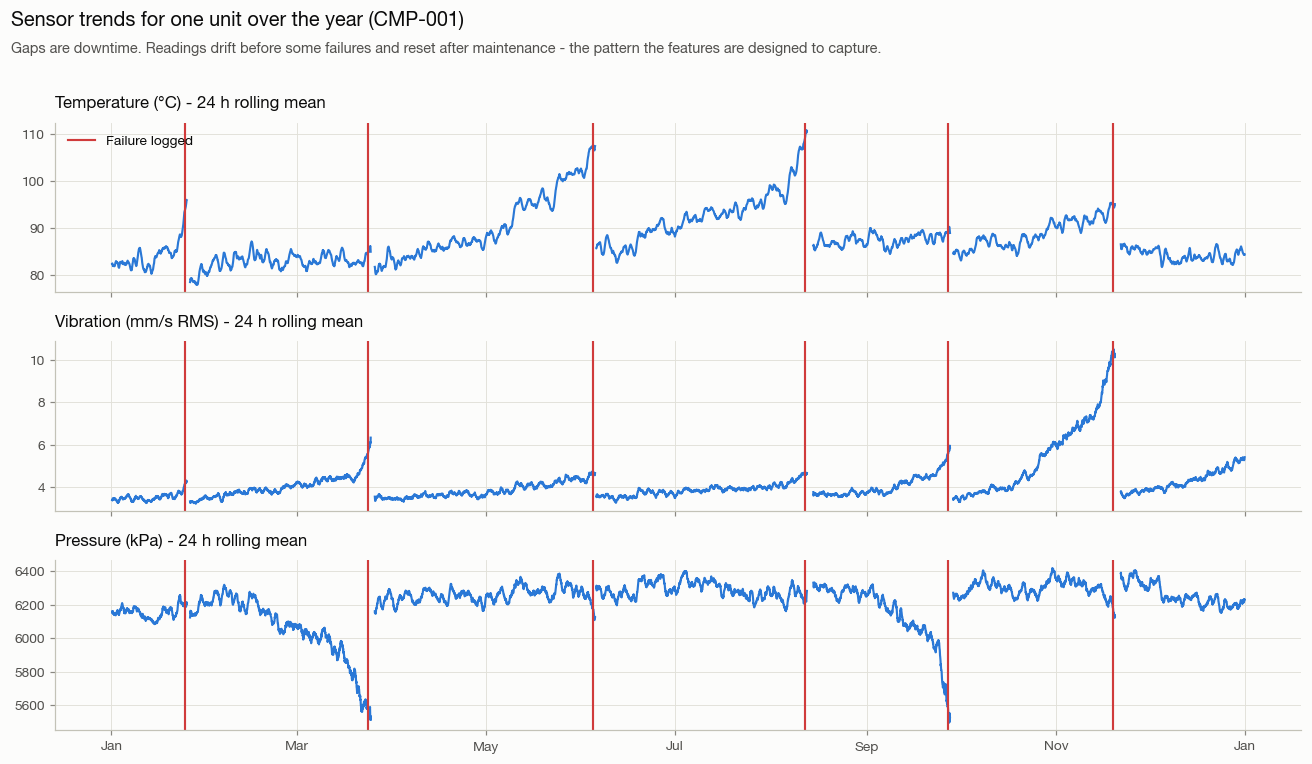

In [8]:
unit = data.failures.groupby("equipment_id").size().idxmax()
show(plotting.fig_unit_timeline(tele, data.failures, data.maintenance, unit))

### 3.3 Relationships between variables and between units

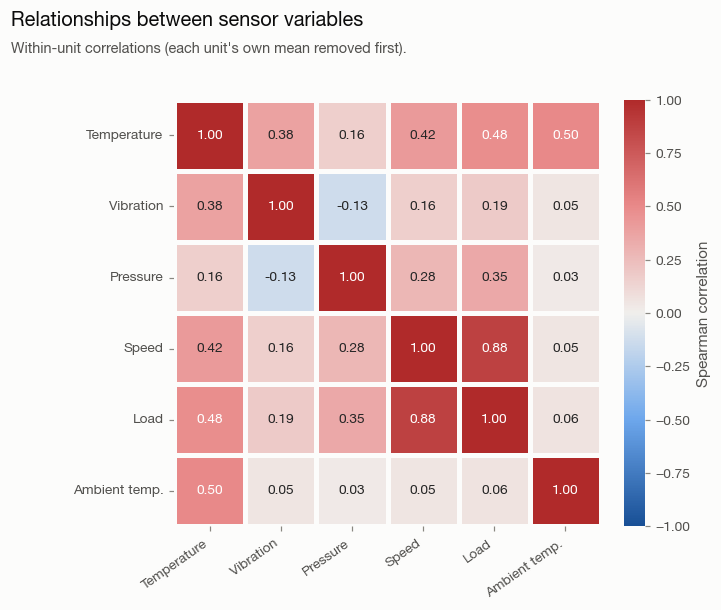

In [9]:
show(plotting.fig_correlation(tele))

Temperature moves with load and with ambient temperature; speed follows load almost perfectly. A hot
bearing on a hot, heavily loaded day is not news. This is why the features below are built on
**condition-adjusted** readings - each sensor with its unit-specific response to load and ambient
temperature removed.

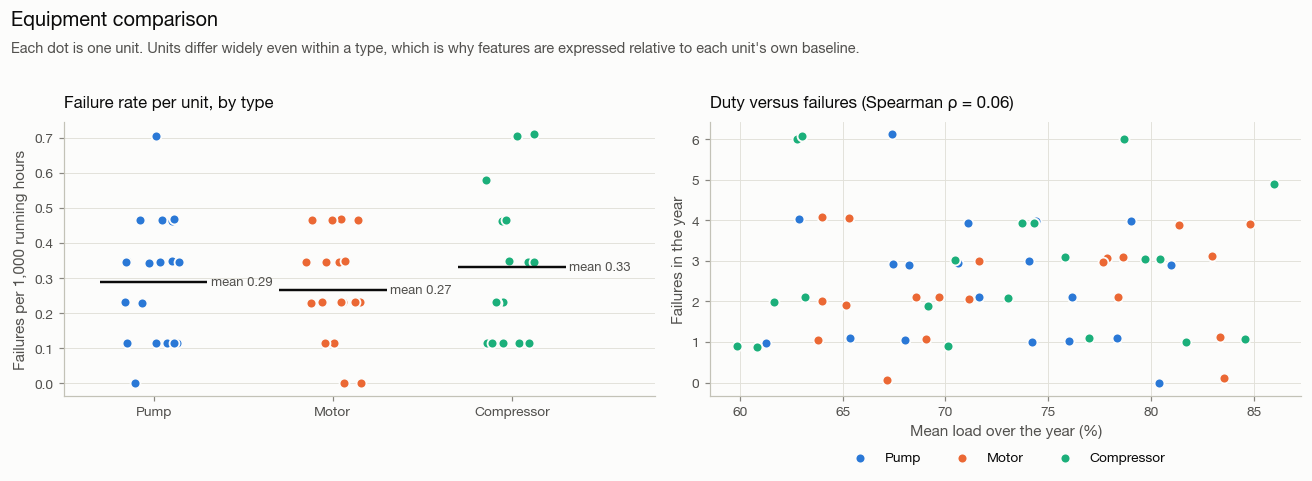

In [10]:
show(plotting.fig_equipment_comparison(tele, data.failures, data.registry))

## 4. Feature engineering

Every feature at time *t* uses only information recorded at or before *t* for that unit.

| Step | What is computed | Leakage control |
|---|---|---|
| Condition adjustment | `sensor - beta_load*load - beta_ambient*ambient`, per unit | Coefficients fitted on the training period only |
| Unit baseline | Expanding median and robust spread (IQR/1.349) | Shifted one row: baseline at *t* uses rows before *t* |
| Level features | Current value and rolling means over 6 h, 24 h, 72 h, 7 d, in unit SDs | Time-based, right-closed windows `(t - w, t]` |
| Variability | Rolling standard deviation (24 h, 72 h) relative to unit spread | Same |
| Trend | Last day minus last week; last 6 h minus the same 24 h earlier | Lag joined on exact timestamp, so downtime gaps cannot misalign it |
| History | Hours since last *completed* maintenance; failures in trailing 90 days | Backward as-of join on work-order completion time |
| Label | Failure logged in `(t, t + 72 h]` | Looks forward; the last 72 h of data are dropped (outcome unknown) |

In [11]:
feats = pipeline.stage_features(data, write=False)
table = feats.table
print(f"{len(table):,} modelling rows x {len(feats.features)} features")
print("positive rate:", f"{feats.label_stats['positive_rate']:.2%}",
      f"(about 1 positive per {feats.label_stats['neg_pos_ratio']:.0f} negatives)")
display(feats.condition_model.groupby("sensor")[["beta_load", "beta_ambient"]].mean()
        .rename(columns={"beta_load": "mean response per % load", "beta_ambient": "mean response per degC ambient"}))

[03:50:53] Fitting condition compensation on the training period and building features ...


[03:51:01] Model table: 510,593 rows, 47 features, positive rate 2.16%


510,593 modelling rows x 47 features
positive rate: 2.16% (about 1 positive per 45 negatives)


,mean response per % load,mean response per degC ambient
sensor,,
pressure_kpa,3.4365,-0.0417
rotational_speed_rpm,2.5258,0.0023
temperature_c,0.2230,0.1200
vibration_mm_s,0.0125,-0.0001


**A leakage test that actually runs.** If features only look backwards, deleting all data after some
time *T* must leave every feature at or before *T* unchanged. The cell below checks this on three
units (the test suite does the same on a separate small fleet).

In [12]:
units = sorted(tele["equipment_id"].unique())[:3]
cutoff = pd.Timestamp("2024-05-01")
sub = tele[tele["equipment_id"].isin(units)]
full = features.build_model_table(sub, data.maintenance, data.failures, data.registry,
                                  feats.condition_model, drop_censored=False)
trunc = features.build_model_table(sub[sub["timestamp"] <= cutoff],
                                   data.maintenance[data.maintenance["end_time"] <= cutoff],
                                   data.failures[data.failures["failure_time"] <= cutoff],
                                   data.registry, feats.condition_model, drop_censored=False)
key = ["equipment_id", "timestamp"]
a = full[full["timestamp"] <= cutoff].set_index(key)[feats.features]
b = trunc.set_index(key)[feats.features].reindex(a.index)
print("rows compared:", len(a))
print("largest absolute difference in any feature:", float((a - b).abs().max().max()))

rows compared: 8301
largest absolute difference in any feature: 0.0


## 5. Validation design

Rows are hourly readings from the same machines, so neighbouring rows are nearly identical. A random
train/test split would put near-copies of test rows into training and report fantasy scores.

* **Chronological split** - train Jan-Jul, validate Aug-Sep, test Oct-Dec.
* **Purge gap** - the last 72 h before each boundary are dropped, because their labels are decided by
  events in the next period.
* **Walk-forward folds** for model selection - three expanding windows, all before the test period.
* **Equipment-grouped CV** as a second opinion - can the model score units it has never seen?

,split,start,end,rows,positive_rows,positive_rate,units
0,train,2024-01-04,2024-07-28 23:00:00,294047,5580,0.0190,60
1,validation,2024-08-01,2024-09-27 23:00:00,81810,2528,0.0309,60
2,test,2024-10-01,2024-12-28 23:00:00,126272,2784,0.0220,60


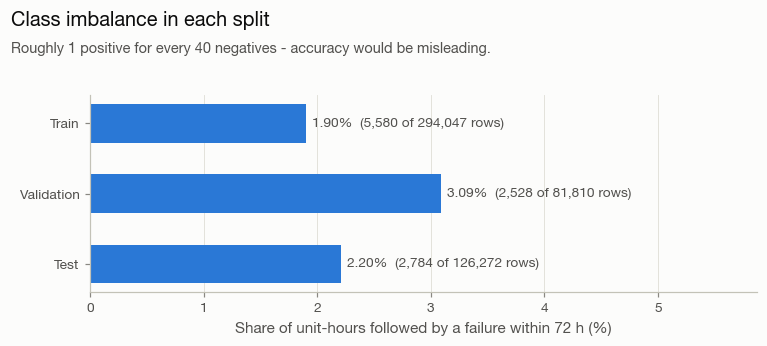

In [13]:
split = feats.split
display(split.summary())
show(plotting.fig_class_balance(split.summary()))

With about 2% positives, a model that never raises an alert is ~98% accurate and useless. Accuracy
is therefore reported but never used to choose anything. Selection uses **PR-AUC**
(average precision), which only rewards ranking the rare positives highly.

## 6. Models

| Model | Role |
|---|---|
| Prevalence baseline | Floor: what "no skill" looks like under this imbalance |
| Sensor-deviation rule | Transparent non-ML baseline: worst adverse deviation of temperature, vibration or pressure from unit baseline |
| Isolation forest | Unsupervised reference: what is achievable if failure labels cannot be trusted |
| Logistic regression | Linear, interpretable baseline model (class-weighted) |
| Random forest | Non-linear, robust to scale (class-weighted) |
| Gradient boosting | Non-linear, handles missing values natively (class-weighted) |

Hyper-parameters come from a small grid scored by mean PR-AUC over the walk-forward folds. This takes
a few minutes.

In [14]:
trained = pipeline.stage_train(feats, save=False)
log = pd.DataFrame(trained.tuning_log)
display(log.style.format({c: "{:.3f}" for c in log.columns if "pr_auc" in c}).hide(axis="index"))
print("Primary model (best mean walk-forward PR-AUC):", modeling.MODEL_LABELS[trained.selected])

[03:51:02] Walk-forward tuning (3 chronological folds) ...


  logistic_regression  {'C': 0.01}                              folds 0.444 0.466 0.610 | mean 0.5064


  logistic_regression  {'C': 0.1}                               folds 0.444 0.463 0.610 | mean 0.5054


  logistic_regression  {'C': 1.0}                               folds 0.437 0.461 0.609 | mean 0.5027


  random_forest        {'min_samples_leaf': 25}                 folds 0.555 0.469 0.567 | mean 0.5304


  random_forest        {'min_samples_leaf': 100}                folds 0.556 0.442 0.551 | mean 0.5165


  gradient_boosting    {'max_depth': 3, 'max_iter': 200}        folds 0.516 0.530 0.526 | mean 0.5240


  gradient_boosting    {'max_depth': 3, 'max_iter': 400}        folds 0.502 0.506 0.490 | mean 0.4991


  gradient_boosting    {'max_depth': 6, 'max_iter': 200}        folds 0.461 0.502 0.548 | mean 0.5036
[03:54:26] Selected primary model: random_forest (mean walk-forward PR-AUC 0.5304)


model,params,fold_1_pr_auc,fold_2_pr_auc,fold_3_pr_auc,mean_pr_auc
logistic_regression,C=0.01,0.444,0.466,0.610,0.506
logistic_regression,C=0.1,0.444,0.463,0.610,0.505
logistic_regression,C=1.0,0.437,0.461,0.609,0.503
random_forest,min_samples_leaf=25,0.555,0.469,0.567,0.530
random_forest,min_samples_leaf=100,0.556,0.442,0.551,0.517
gradient_boosting,"max_depth=3, max_iter=200",0.516,0.530,0.526,0.524
gradient_boosting,"max_depth=3, max_iter=400",0.502,0.506,0.490,0.499
gradient_boosting,"max_depth=6, max_iter=200",0.461,0.502,0.548,0.504


Primary model (best mean walk-forward PR-AUC): Random forest


## 7. Evaluation on the held-out test period

Thresholds are chosen on the validation period (maximum F1 for each model) and then applied
unchanged to the test period.

In [15]:
ev = pipeline.stage_evaluate(data, feats, trained, write=False, extras=False)
comp = ev.tables["model_comparison"].copy()
comp["model"] = comp["model"].map(modeling.MODEL_LABELS)
cols = ["model", "validation_pr_auc", "pr_auc", "roc_auc", "precision", "recall", "f1", "accuracy", "alert_rate"]
display(comp[cols].style.format({c: "{:.3f}" for c in cols[1:]}).hide(axis="index"))

[03:54:28] Scoring validation and test periods ...


[03:54:38] Cluster bootstrap confidence intervals ...


model,validation_pr_auc,pr_auc,roc_auc,precision,recall,f1,accuracy,alert_rate
Prevalence baseline,nan,0.022,0.500,0.000,0.000,0.000,0.978,0.000
Sensor-deviation rule,0.388,0.184,0.896,0.184,0.536,0.273,0.937,0.064
Isolation forest (unsupervised),0.411,0.268,0.876,0.210,0.403,0.276,0.953,0.042
Logistic regression,0.610,0.261,0.912,0.325,0.476,0.387,0.967,0.032
Random forest,0.567,0.500,0.927,0.463,0.483,0.473,0.976,0.023
Gradient boosting,0.526,0.481,0.910,0.480,0.447,0.463,0.977,0.021


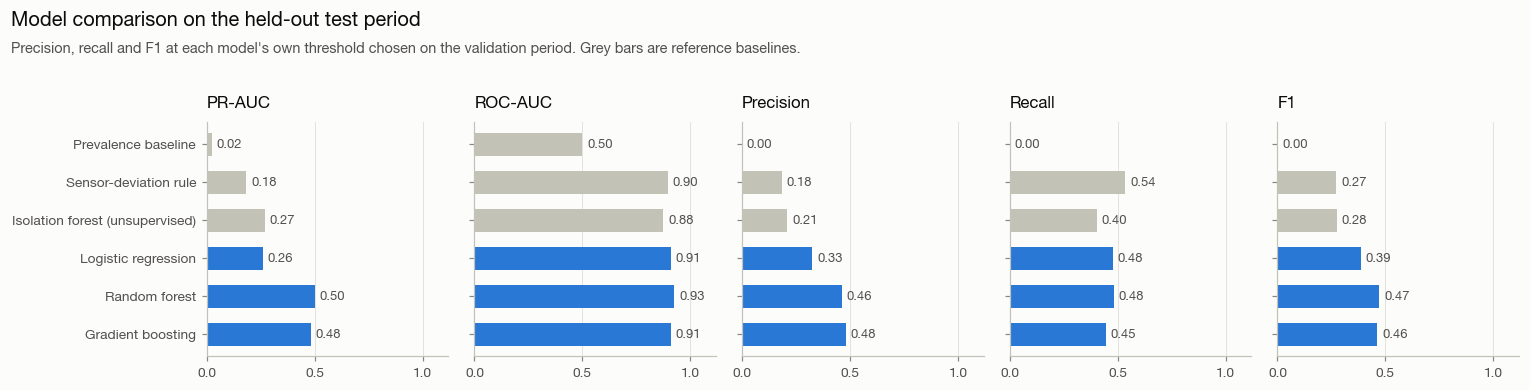

In [16]:
show(plotting.fig_model_comparison(ev.tables["model_comparison"]))

Note the accuracy column: the baseline that never alerts scores about 98% - as high as, or higher
than, the trained models. That one row is the argument for not optimising accuracy.

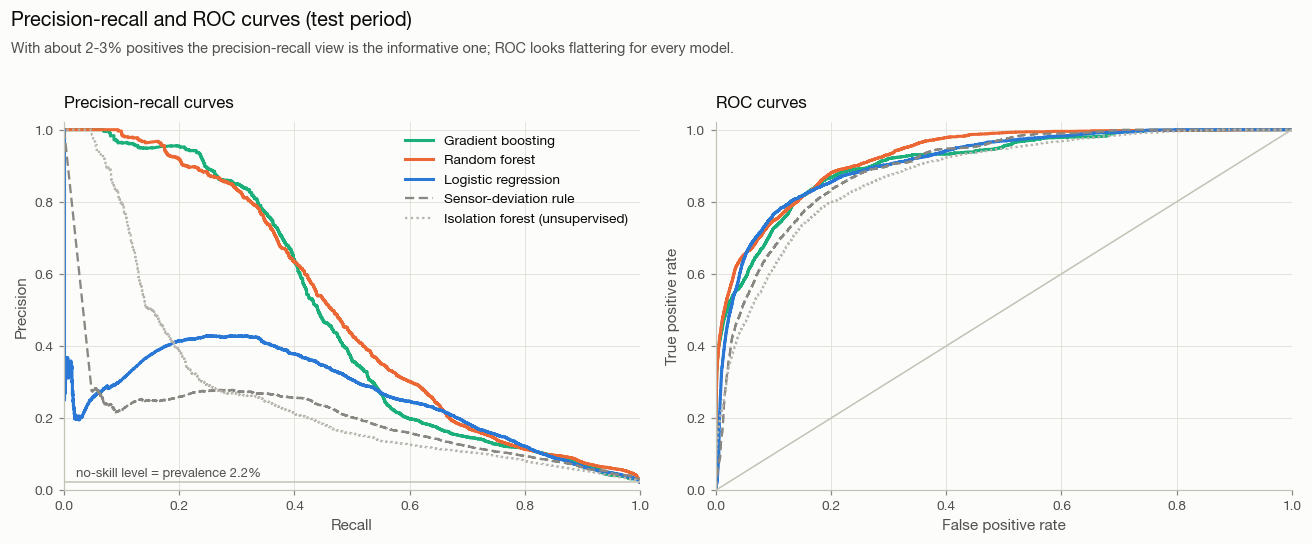

In [17]:
show(plotting.fig_pr_roc(split.test[C.TARGET].to_numpy(), ev.scores_test))

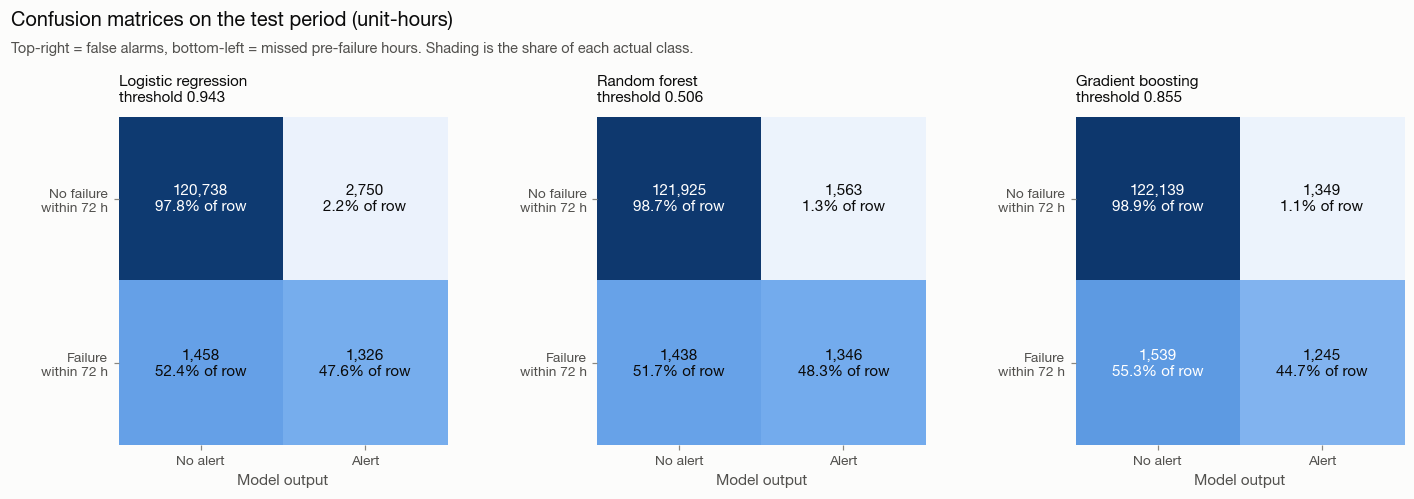

In [18]:
m = ev.tables["model_comparison"].set_index("model")
cms = {n: {**{k: int(m.loc[n, k]) for k in ("tn", "fp", "fn", "tp")}, "threshold": ev.thresholds[n]}
       for n in modeling.SUPERVISED}
show(plotting.fig_confusion_matrices(cms))

### Why these metrics, and what each kind of error costs

No dollar figures are used here - none exist for simulated equipment and inventing them would be
misleading. The trade-off can still be reasoned about:

* A **false positive** sends a qualified person to look at a healthy machine. The cost is their
  time and, if it happens too often, their trust: a list that is usually wrong stops being read.
  **Precision** measures this.
* A **false negative** is a failure nobody was pointed towards. The cost is whatever an unplanned
  stop costs over a planned one. **Recall** measures this.
* The two are usually very unequal, and how unequal depends on the equipment's criticality,
  redundancy and inspection cost - information the operator has and the analyst does not. That is
  why the output is a **ranked score with two thresholds** rather than a single yes/no.

### Uncertainty

Rows from one machine are not independent, so the bootstrap resamples **whole units**.

In [19]:
ci = pd.DataFrame([{"model": modeling.MODEL_LABELS[n], "metric": k.upper().replace("_", "-"),
                    "point": v["point"], "95% CI low": v["ci_low"], "95% CI high": v["ci_high"]}
                   for n, d in ev.metrics["bootstrap_ci_95"].items() for k, v in d.items()])
display(ci.style.format({"point": "{:.3f}", "95% CI low": "{:.3f}", "95% CI high": "{:.3f}"}).hide(axis="index"))

model,metric,point,95% CI low,95% CI high
Logistic regression,PR-AUC,0.261,0.161,0.547
Logistic regression,ROC-AUC,0.912,0.873,0.943
Random forest,PR-AUC,0.500,0.408,0.615
Random forest,ROC-AUC,0.927,0.897,0.956
Gradient boosting,PR-AUC,0.481,0.362,0.594
Gradient boosting,ROC-AUC,0.910,0.865,0.947


### Event-level view

Maintenance teams think in failures and inspections, not unit-hours. For the primary model:

threshold,failures in test,flagged beforehand,event recall,median lead time (h),row precision,row recall,false-alert days per unit-month,share of alert unit-days followed by failure
High (>= 0.506),38,31,81.6%,50,46.3%,48.3%,0.73,42.1%
Medium (>= 0.140),38,34,89.5%,72,12.4%,78.0%,4.82,13.3%


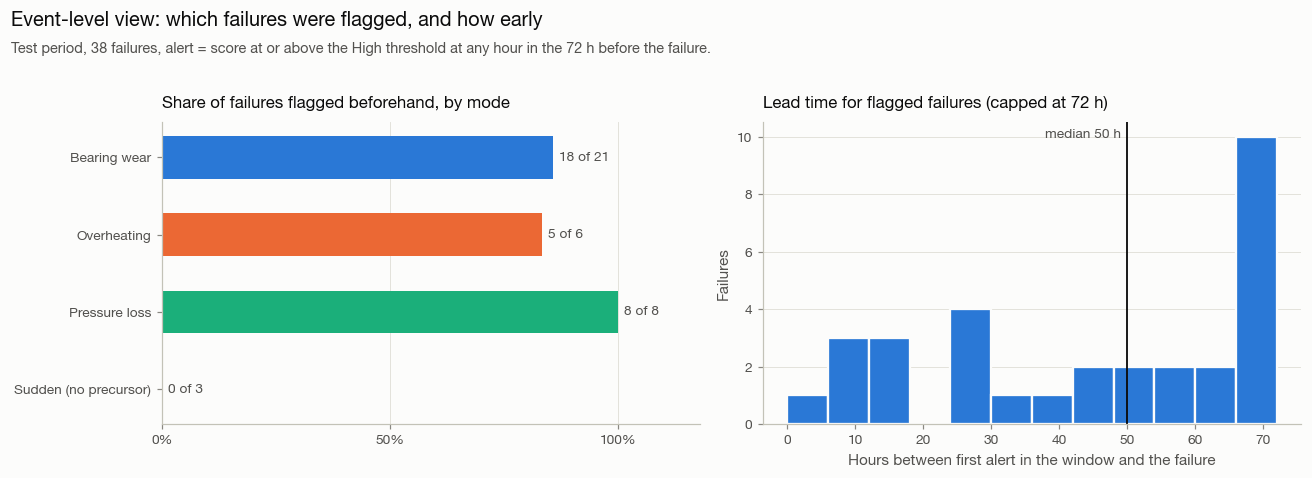

In [20]:
rows = []
for tag in ("high", "medium"):
    r, e = ev.metrics[f"row_level_{tag}"], ev.metrics[f"event_level_{tag}"]
    rows.append({"threshold": f"{tag.capitalize()} (>= {r['threshold']:.3f})",
                 "failures in test": e["n_failures"], "flagged beforehand": e["failures_flagged"],
                 "event recall": e["event_recall"], "median lead time (h)": e["median_lead_time_hours"],
                 "row precision": r["precision"], "row recall": r["recall"],
                 "false-alert days per unit-month": e["false_alert_days_per_unit_month"],
                 "share of alert unit-days followed by failure": e["unit_day_precision"]})
display(pd.DataFrame(rows).style.format({"event recall": "{:.1%}", "row precision": "{:.1%}",
        "row recall": "{:.1%}", "false-alert days per unit-month": "{:.2f}",
        "share of alert unit-days followed by failure": "{:.1%}", "median lead time (h)": "{:.0f}"}).hide(axis="index"))
show(plotting.fig_event_detection(ev.tables["events_test"]))

## 8. Interpretation

### 8.1 Which variables the models rely on

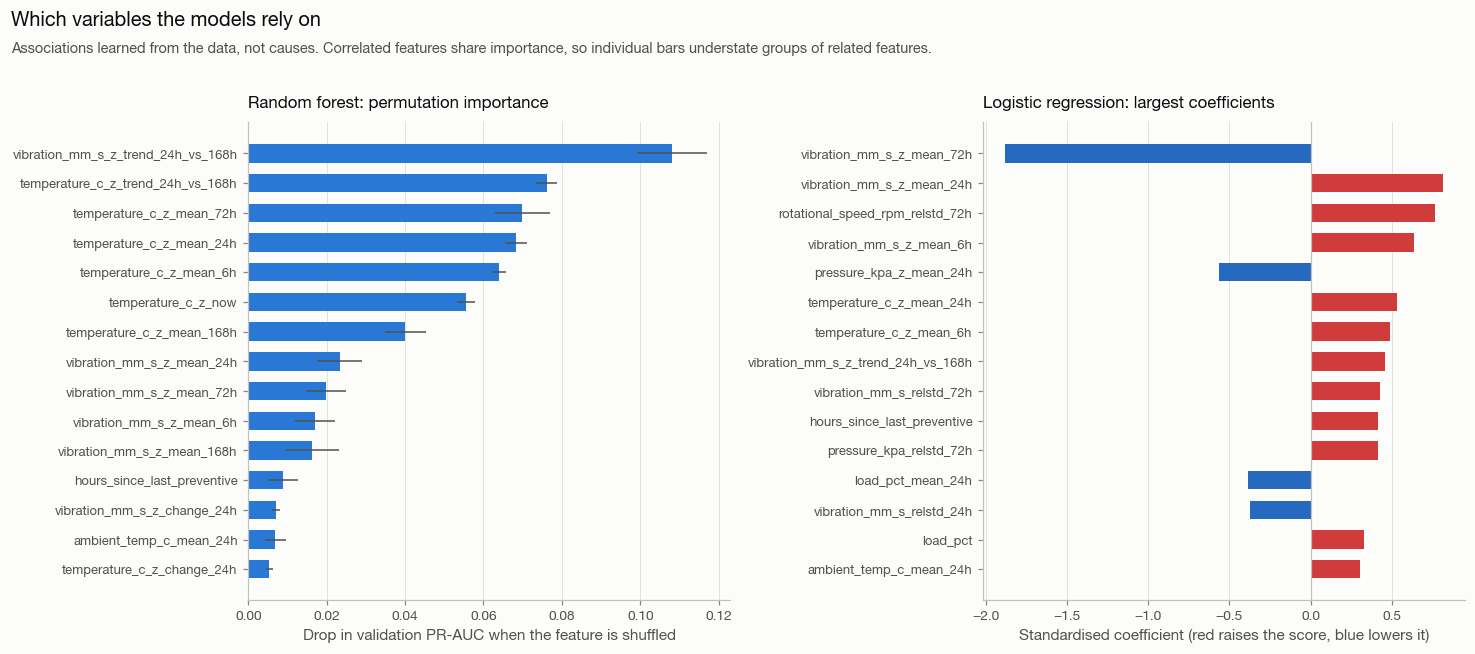

In [21]:
perm = pd.read_csv(C.TABLES_DIR / "permutation_importance.csv")
coefs = pd.read_csv(C.TABLES_DIR / "logistic_coefficients.csv")
show(plotting.fig_feature_importance(perm, coefs, modeling.MODEL_LABELS[ev.metrics["selected_model"]]))

These are statements about what the fitted models *use*, not about what causes failures.
Correlated features (for example the 24 h and 72 h means of the same sensor) share importance, and
opposite-signed coefficients on neighbouring windows in the logistic model are the model building a
trend out of two levels, not evidence that a higher 72 h mean is protective.

### 8.2 Where it performs well and where it performs poorly

In [22]:
display(Markdown("**By equipment type** (primary model, High threshold)"))
display(ev.tables["by_equipment_type"].style.format({c: "{:.3f}" for c in
        ["positive_rate", "pr_auc", "roc_auc", "precision", "recall", "f1"]}).hide(axis="index"))
display(Markdown("**By failure mode** - rows are pre-failure hours, events are failures"))
display(ev.tables["by_failure_mode"].style.format({"row_recall": "{:.1%}", "event_recall": "{:.1%}"}).hide(axis="index"))
display(Markdown("**Recall by time to failure**"))
display(ev.tables["recall_by_time_to_failure"].style.format({"row_recall": "{:.1%}"}).hide(axis="index"))

**By equipment type** (primary model, High threshold)

equipment_type,rows,positive_rate,pr_auc,roc_auc,precision,recall,f1
compressor,41961,0.027,0.449,0.893,0.374,0.448,0.407
motor,42130,0.021,0.582,0.951,0.732,0.465,0.569
pump,42181,0.018,0.567,0.964,0.436,0.555,0.489


**By failure mode** - rows are pre-failure hours, events are failures

next_failure_mode,positive_rows,flagged_rows,row_recall,failures,failures_flagged,event_recall
bearing_wear,1512,704,46.6%,21,18,85.7%
overheating,432,203,47.0%,6,5,83.3%
pressure_loss,624,439,70.4%,8,8,100.0%
sudden_no_precursor,216,0,0.0%,3,0,0.0%


**Recall by time to failure**

ttf_bin,positive_rows,row_recall
0-24 h,924,68.0%
24-48 h,936,47.1%
48-72 h,924,30.0%


### 8.3 False alarms and missed failures

Because the data is simulated, false alarms can be compared with the simulator's hidden wear state -
something that is never possible with real equipment.

,value
false-alarm unit-hours (High threshold),"1,563"
... of which a failure followed 3-7 days later,29.6%
... of which hidden wear was already in the hazardous range,100.0%
same share among all non-failure hours,32.7%
share of false alarms coming from just 3 units,48.1%


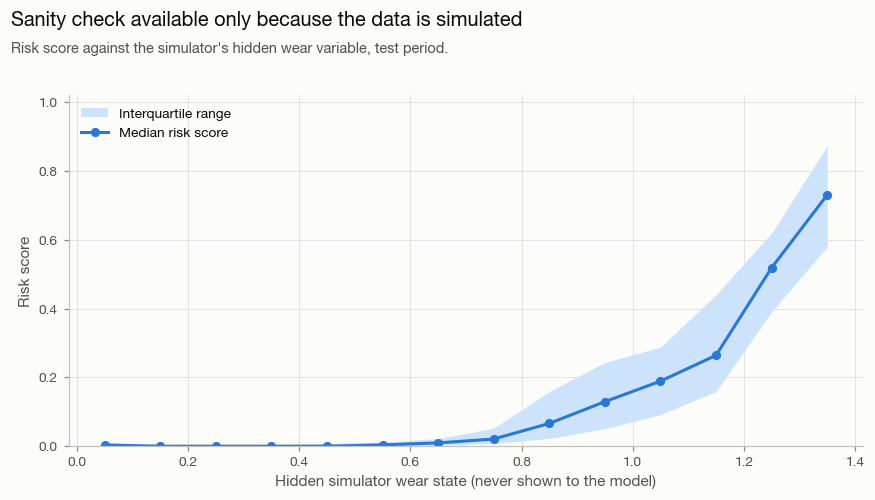

In [23]:
fa = ev.metrics["false_alarm_anatomy"]
display(pd.Series({
    "false-alarm unit-hours (High threshold)": f"{fa['false_alarm_rows']:,}",
    "... of which a failure followed 3-7 days later": f"{fa['share_with_failure_within_3_to_7_days']:.1%}",
    "... of which hidden wear was already in the hazardous range": f"{fa['share_with_latent_wear_above_hazard_onset']:.1%}",
    "same share among all non-failure hours": f"{fa['share_of_all_negative_rows_with_latent_wear_above_hazard_onset']:.1%}",
    "share of false alarms coming from just 3 units": f"{fa['top3_units_share_of_false_alarm_rows']:.1%}",
}, name="value").to_frame())
truth = data_loading.load_ground_truth()
show(plotting.fig_score_vs_latent_wear(ev.scored_test.merge(truth, on=["equipment_id", "timestamp"], how="left")))

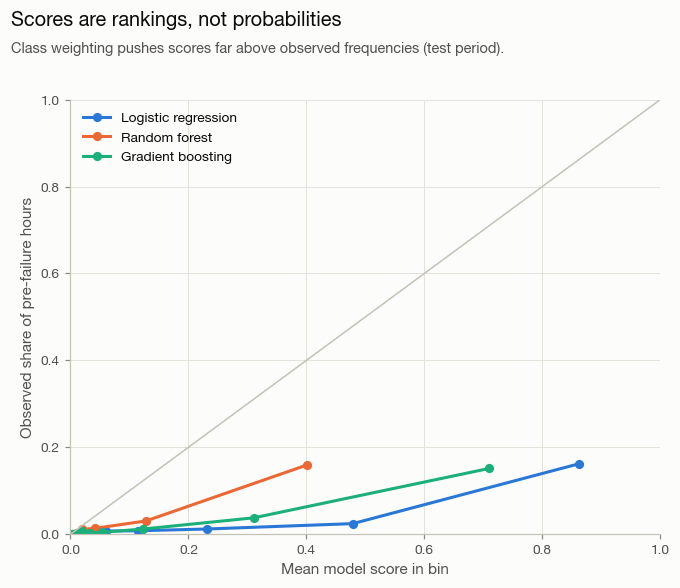

In [24]:
show(plotting.fig_calibration(split.test[C.TARGET].to_numpy(), ev.scores_test))

The scores are not probabilities - class weighting inflates them. A score of 0.8 does **not** mean an
80% chance of failure. They are used only to rank units and to compare against thresholds.

## 9. Risk ranking

Two thresholds, both fixed on the validation period before the test period was scored:

* **High** - score at or above the threshold that maximised F1 on validation.
* **Medium** - score at or above the highest threshold that still caught at least 80% of
  pre-failure hours on validation.
* **Low** - everything else.

Medium >= 0.140   High >= 0.506


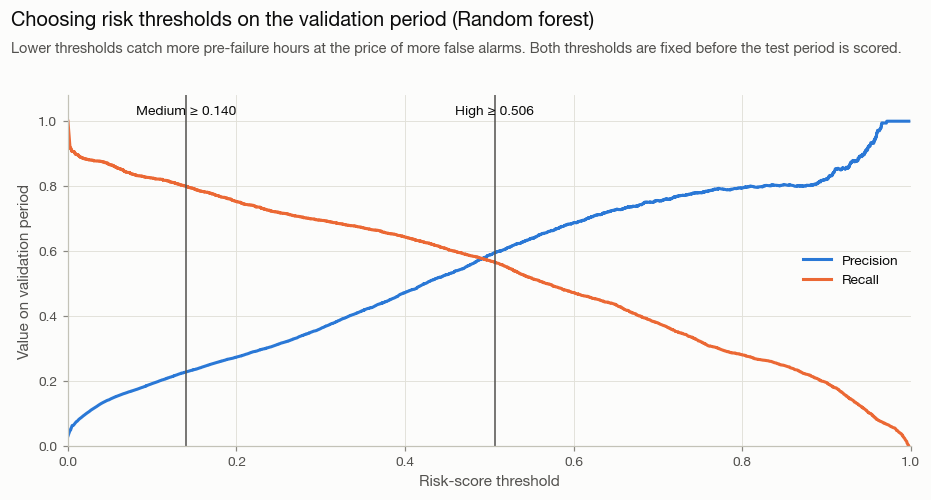

In [25]:
print(f"Medium >= {ev.t_medium:.3f}   High >= {ev.t_high:.3f}")
show(plotting.fig_threshold_tradeoff(split.val[C.TARGET].to_numpy(), ev.scores_val[ev.metrics["selected_model"]],
                                ev.t_medium, ev.t_high, modeling.MODEL_LABELS[ev.metrics["selected_model"]]))

In [26]:
risk_out = pipeline.stage_risk(data, ev, write=False)
ranking = risk_out["ranking"]
print("Snapshot:", risk_out["snapshot"], "| units per category:", risk_out["category_counts"])
ranking_cols = ["rank", "equipment_id", "equipment_type", "risk_score", "risk_score_change_24h", "risk_category",
        "relevant_sensor_trends", "hours_since_last_maintenance", "suggested_review_priority"]
with pd.option_context("display.max_colwidth", 90):
    display(ranking[ranking_cols].head(12).style.format({"risk_score": "{:.3f}", "risk_score_change_24h": "{:+.3f}",
            "hours_since_last_maintenance": "{:.0f}"}).hide(axis="index"))

[03:55:11] Building risk ranking ...


Snapshot: 2024-12-28 23:00:00 | units per category: {'Low': 45, 'Medium': 10, 'High': 4, 'No current data': 1}


rank,equipment_id,equipment_type,risk_score,risk_score_change_24h,risk_category,relevant_sensor_trends,hours_since_last_maintenance,suggested_review_priority
1,PMP-018,pump,0.882,+0.075,High,"pressure 4.6 SD below unit baseline, falling vs last 7 days (-1.1 SD); vibration 2.1 SD above unit baseline, rising vs last 7 days (+0.8 SD)",868,Priority 1 - suggest reviewing first
2,MTR-001,motor,0.817,-0.003,High,"pressure 6.6 SD below unit baseline, falling vs last 7 days (-1.5 SD); vibration 4.2 SD above unit baseline, rising vs last 7 days (+1.1 SD)",1451,Priority 1 - suggest reviewing first
3,PMP-004,pump,0.605,+0.405,High,"vibration 4.4 SD above unit baseline, rising vs last 7 days (+0.6 SD); temperature 1.8 SD above unit baseline, steady vs last 7 days (+0.3 SD)",2310,Priority 1 - suggest reviewing first
4,CMP-017,compressor,0.546,-0.067,High,"pressure 8.0 SD below unit baseline, falling vs last 7 days (-1.1 SD)",2012,Priority 1 - suggest reviewing first
5,CMP-012,compressor,0.405,+0.084,Medium,"pressure 4.1 SD below unit baseline, steady vs last 7 days (-0.5 SD)",1695,Priority 2 - suggest reviewing when scheduling allows
6,PMP-012,pump,0.388,-0.052,Medium,"pressure 3.6 SD below unit baseline, steady vs last 7 days (-0.4 SD)",1737,Priority 2 - suggest reviewing when scheduling allows
7,PMP-009,pump,0.374,+0.146,Medium,"pressure 2.2 SD below unit baseline, steady vs last 7 days (+0.0 SD); vibration 2.0 SD above unit baseline, steady vs last 7 days (+0.4 SD)",1361,Priority 2 - suggest reviewing when scheduling allows
8,CMP-014,compressor,0.339,+0.001,Medium,"pressure 3.5 SD below unit baseline, steady vs last 7 days (-0.3 SD)",1458,Priority 2 - suggest reviewing when scheduling allows
9,CMP-004,compressor,0.324,-0.102,Medium,"pressure 3.9 SD below unit baseline, falling vs last 7 days (-0.7 SD); vibration 1.7 SD above unit baseline, steady vs last 7 days (+0.1 SD)",1302,Priority 2 - suggest reviewing when scheduling allows
10,MTR-015,motor,0.314,-0.029,Medium,"vibration 2.1 SD above unit baseline, steady vs last 7 days (+0.1 SD); temperature 1.5 SD above unit baseline, steady vs last 7 days (+0.2 SD)",1594,Priority 2 - suggest reviewing when scheduling allows


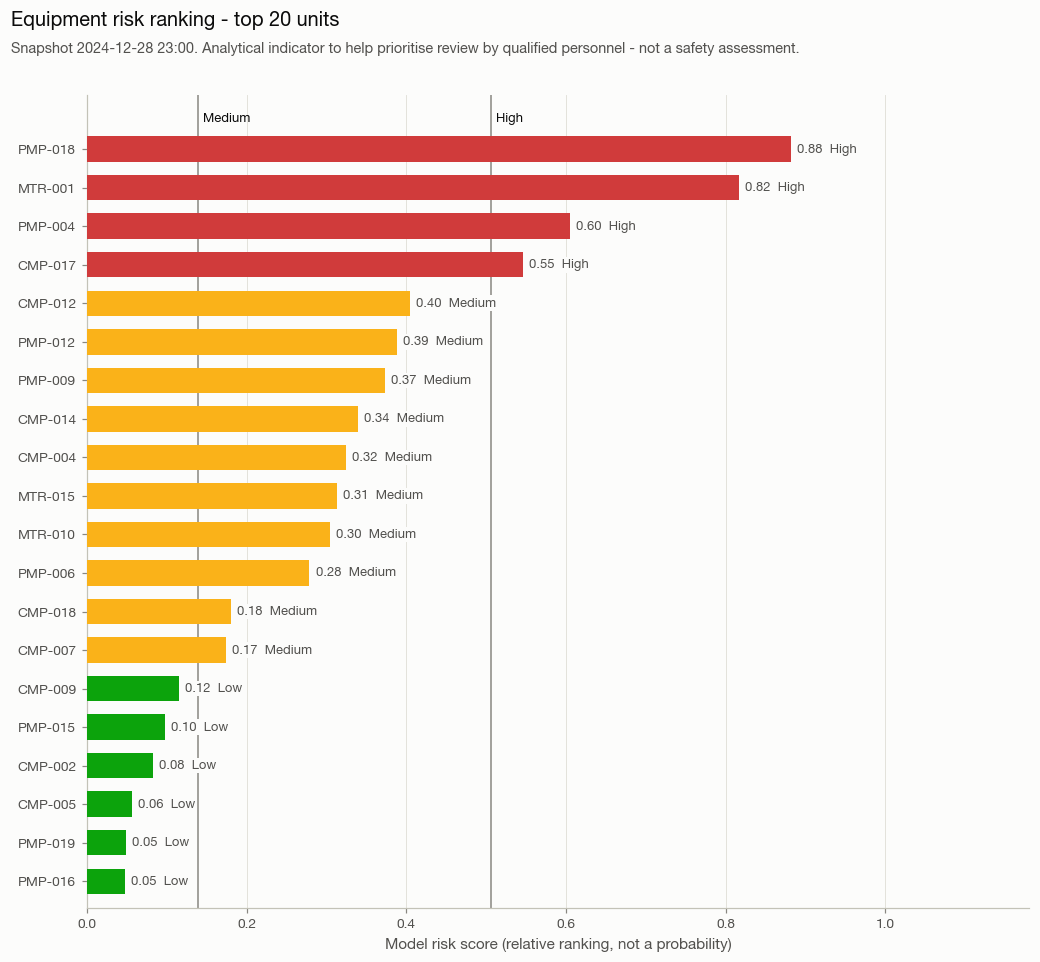

In [27]:
show(plotting.fig_risk_ranking(ranking, ev.t_medium, ev.t_high, risk_out["snapshot"]))

> **How to read this table.** It is an analytical indicator for qualified personnel to review. A
> "High" label means the unit's recent sensor pattern resembles patterns that preceded failures in
> the historical (simulated) data. It is not a finding that the unit is failing, not a safety
> assessment and not an instruction to act.

**Does the ranking carry information?** A back-test over every Monday in the test period: take the
five highest-scoring units and see how many had a failure logged within the following 72 hours.

In [28]:
bs = risk_out["backtest_summary"]
display(pd.Series({
    "weekly snapshots": bs["snapshots"], "units surfaced (5 per week)": bs["units_reviewed"],
    "of those, followed by a failure within 72 h": bs["hits"],
    "precision at 5": f"{bs['precision_at_k']:.1%}", "expected from random picks": f"{bs['base_rate']:.1%}",
    "lift over random": f"{bs['lift_over_random']:.1f}x",
    "share of upcoming failures that were in the top 5": f"{bs['share_of_upcoming_failures_in_top_k']:.1%}",
}, name="value").to_frame())
display(risk_out["category_outcomes"].style.format({"followed_by_failure_within_72h": "{:.1%}",
        "share_of_unit_hours": "{:.1%}", "unit_hours": "{:,}"}).hide(axis="index"))

,value
weekly snapshots,12
units surfaced (5 per week),60
"of those, followed by a failure within 72 h",10
precision at 5,16.7%
expected from random picks,2.0%
lift over random,8.4x
share of upcoming failures that were in the top 5,71.4%


category,unit_hours,followed_by_failure_within_72h,share_of_unit_hours
Low,"108,814",0.6%,86.2%
Medium,"14,549",5.7%,11.5%
High,"2,909",46.3%,2.3%


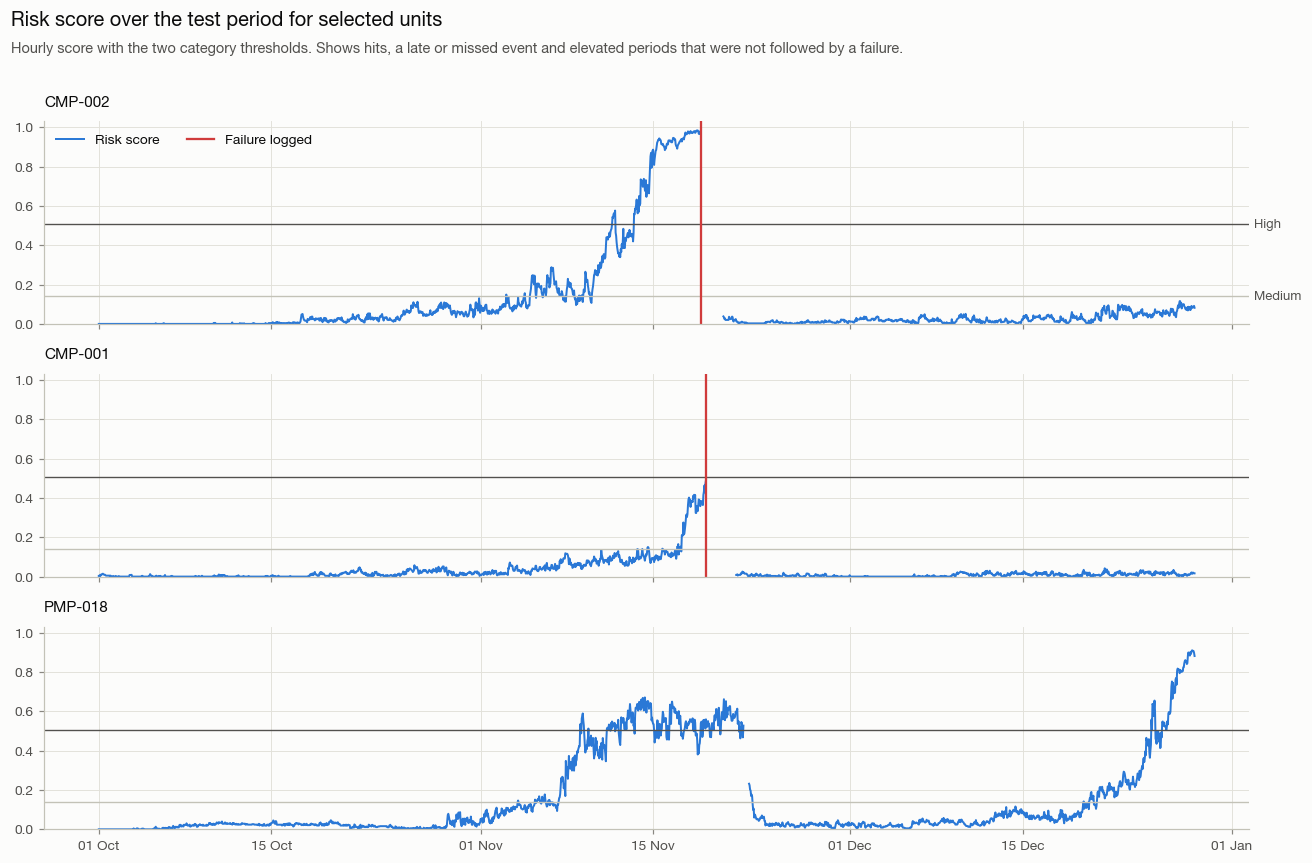

In [29]:
units = pipeline._example_units(ev.scored_test, ev.tables["events_test"], ev.t_high)
show(plotting.fig_risk_timeline(ev.scored_test, data.failures, units, ev.t_medium, ev.t_high))

## 10. Robustness checks

These three tables are produced by the pipeline (they take several minutes) and loaded here.

**Fresh-seed replication.** The whole recipe - same features, same hyper-parameters, same threshold
rule - re-run on three newly simulated fleets that were never looked at during development.

In [30]:
rep = pd.read_csv(C.TABLES_DIR / "replication_fresh_seeds.csv")
rep["model"] = rep["model"].map(modeling.MODEL_LABELS)
fmt = {c: "{:.3f}" for c in ["test_prevalence", "pr_auc", "roc_auc", "precision", "recall", "f1", "event_recall",
                              "false_alert_days_per_unit_month"]}
display(rep.style.format(fmt).hide(axis="index"))
display(rep.groupby("model")[["pr_auc", "roc_auc", "f1", "event_recall"]].agg(["mean", "min", "max"]).round(3))

seed,model,test_failures,test_prevalence,pr_auc,roc_auc,precision,recall,f1,event_recall,false_alert_days_per_unit_month
7,Logistic regression,40,0.023,0.604,0.957,0.440,0.696,0.539,0.950,1.066
7,Random forest,40,0.023,0.621,0.957,0.680,0.522,0.590,0.925,0.365
7,Gradient boosting,40,0.023,0.607,0.957,0.614,0.548,0.579,0.900,0.508
2025,Logistic regression,45,0.025,0.536,0.931,0.614,0.448,0.518,0.911,0.416
2025,Random forest,45,0.025,0.618,0.936,0.700,0.555,0.619,0.867,0.416
2025,Gradient boosting,45,0.025,0.552,0.924,0.668,0.428,0.522,0.844,0.428
31337,Logistic regression,45,0.025,0.419,0.911,0.429,0.418,0.423,0.778,0.673
31337,Random forest,45,0.025,0.591,0.923,0.530,0.613,0.568,0.822,0.861
31337,Gradient boosting,45,0.025,0.606,0.916,0.624,0.565,0.593,0.844,0.604


pr_auc               roc_auc                   f1               event_recall              
                      mean    min    max    mean    min    max   mean    min    max         mean    min    max
model                                                                                                         
Gradient boosting   0.5880 0.5520 0.6070  0.9330 0.9160 0.9570 0.5650 0.5220 0.5930       0.8630 0.8440 0.9000
Logistic regression 0.5190 0.4190 0.6040  0.9330 0.9110 0.9570 0.4940 0.4230 0.5390       0.8800 0.7780 0.9500
Random forest       0.6100 0.5910 0.6210  0.9390 0.9230 0.9570 0.5930 0.5680 0.6190       0.8710 0.8220 0.9250

**Equipment-grouped cross-validation** - every unit is scored by a model that never saw it.

In [31]:
g = pd.read_csv(C.TABLES_DIR / "grouped_cv_by_equipment.csv"); g["model"] = g["model"].map(modeling.MODEL_LABELS)
display(g.style.format({c: "{:.3f}" for c in g.columns if c.startswith("pr_auc")}).hide(axis="index"))

model,pr_auc_mean,pr_auc_std,pr_auc_min,pr_auc_max,folds
Logistic regression,0.549,0.088,0.415,0.631,5
Random forest,0.559,0.078,0.424,0.643,5
Gradient boosting,0.515,0.082,0.405,0.604,5


**Ablation** - what happens if absolute sensor levels are added to the unit-normalised features?

In [32]:
ab = pd.read_csv(C.TABLES_DIR / "ablation_absolute_features.csv"); ab["model"] = ab["model"].map(modeling.MODEL_LABELS)
display(ab.style.format({c: "{:.3f}" for c in ab.columns if "pr_auc" in c}).hide(axis="index"))

model,val_pr_auc_unit_normalised,val_pr_auc_plus_absolute,test_pr_auc_unit_normalised,test_pr_auc_plus_absolute
Logistic regression,0.610,0.616,0.261,0.272
Random forest,0.567,0.574,0.500,0.454
Gradient boosting,0.526,0.573,0.481,0.463


## 11. Limitations and business reading

**Limitations**

* **Synthetic data.** None of these results is evidence about real equipment. The simulator has
  three degradation modes, instant sensor response and no sensor drift; reality has more of
  everything.
* **Failure frequency is inflated** (about 2.5 failures per unit-year) to give enough events. Real
  fleets fail far less often, which makes both learning and evaluation harder.
* **Few events.** The test period contains only a few dozen failures, so event-level figures move by
  several points if one or two failures change. The confidence intervals and the replication table
  are the honest summary, not any single number.
* **Development contamination.** Test-period scores were looked at while debugging the feature
  pipeline. The fresh-seed replication exists to give an estimate that is free of that.
* **The modeller wrote the simulator.** Feature ideas were informed by knowing how the data was made.
* **Scores are not probabilities** and thresholds would need re-setting for any real deployment.
* **No causal claims.** Feature importance describes the model, not the machine.

**How this kind of analysis could support maintenance work** - framed as possibilities, with no
claimed savings or downtime reduction, because none were measured:

* *Inspection prioritisation* - a short, ranked list with the sensor evidence behind each entry.
* *Maintenance planning* - visibility of units trending away from their own baseline between
  scheduled preventive work.
* *Equipment monitoring* - unit-relative, condition-adjusted indicators instead of one fixed alarm
  limit for dissimilar machines.
* *Operational reporting* - a consistent weekly view of how many units sit in each category.

See `reports/model_evaluation_report.md` and `reports/business_analysis.md` for the full discussion.